# Breathing Beijing
### Exploratory analysis of four years of multi-site air-quality records and an LSTM model that forecasts PM2.5 six hours ahead

*Naveena B (24AD070) | III Year B.Tech. AI and Data Science | U21ADP05 Exploratory Data Analysis and Visualization, Assignment II*

**Data:** Beijing Multi-Site Air Quality (UCI Machine Learning Repository, dataset 501). Hourly readings from
12 state-controlled monitoring sites, 1 March 2013 to 28 February 2017: 420,768 rows and 18 fields
(six pollutants, five weather variables, wind direction, timestamp parts and station name).

**Question.** How do PM2.5 levels vary across time, space and weather in Beijing, and can a recurrent
neural network turn the last day of observations into a useful short-term warning?

The analysis is written as a small Python package (`src/airq`) so that this notebook reads as a narrative.
The seven stages of visualization (Fry) appear in order: **acquire** and **parse** (section 1),
**filter** (section 2), **mine** (sections 3 to 6 and 8), **represent** and **refine** (every figure)
and **interact** (section 7, `dashboard/index.html`).

In [1]:
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

from airq import config as C, data as D, stats_tools as S, viz as V, viz_results as VR, model as M

C.apply_style()
RES = {}                       # every number quoted in the report is collected here
pd.set_option("display.width", 160)


def jround(x, k=3):
    return float(np.round(float(x), k))

## 1. Acquire and parse

In [2]:
raw = D.load_raw()
print(raw.shape)
dictionary = pd.DataFrame({
    "Field": ["No", "year", "month", "day", "hour", "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
              "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM", "station"],
    "Type": ["Integer (row id)", "Integer", "Integer", "Integer", "Integer"] + ["Continuous"] * 10 +
            ["Categorical (16 levels)", "Continuous", "Categorical (12 levels)"],
    "Unit": ["-", "-", "-", "-", "-", "ug/m3", "ug/m3", "ug/m3", "ug/m3", "ug/m3", "ug/m3",
             "deg C", "hPa", "deg C", "mm", "compass point", "m/s", "-"],
    "Meaning": ["Row number within a station file", "Year of record", "Month", "Day of month", "Hour (0-23)",
                "Fine particulate matter (diameter <= 2.5 um)", "Inhalable particles (<= 10 um)",
                "Sulphur dioxide", "Nitrogen dioxide", "Carbon monoxide", "Ozone",
                "Air temperature", "Air pressure", "Dew-point temperature", "Hourly precipitation",
                "Wind direction", "Wind speed", "Monitoring site"],
})
dictionary.to_csv(C.RES_DIR / "data_dictionary.csv", index=False)
dictionary

(420768, 19)


,Field,Type,Unit,Meaning
0,No,Integer (row id),-,Row number within a station file
1,year,Integer,-,Year of record
2,month,Integer,-,Month
3,day,Integer,-,Day of month
4,hour,Integer,-,Hour (0-23)
5,PM2.5,Continuous,ug/m3,Fine particulate matter (diameter <= 2.5 um)
6,PM10,Continuous,ug/m3,Inhalable particles (<= 10 um)
7,SO2,Continuous,ug/m3,Sulphur dioxide
8,NO2,Continuous,ug/m3,Nitrogen dioxide
9,CO,Continuous,ug/m3,Carbon monoxide


## 2. Filter: data quality, missing values, outliers and cleaning

{
 "rows": 420768,
 "stations": 12,
 "start": "2013-03-01 00:00:00",
 "end": "2017-02-28 23:00:00",
 "exact_duplicates": 0,
 "key_duplicates": 0,
 "hours_per_station": 35064,
 "complete_index": true,
 "missing_counts": {
  "PM2.5": 8739,
  "PM10": 6449,
  "SO2": 9021,
  "NO2": 12116,
  "CO": 20701,
  "O3": 13277,
  "TEMP": 398,
  "PRES": 393,
  "DEWP": 403,
  "RAIN": 390,
  "WSPM": 318,
  "wd": 1822
 },
 "missing_pct": {
  "PM2.5": 2.08,
  "PM10": 1.53,
  "SO2": 2.14,
  "NO2": 2.88,
  "CO": 4.92,
  "O3": 3.16,
  "TEMP": 0.09,
  "PRES": 0.09,
  "DEWP": 0.1,
  "RAIN": 0.09,
  "WSPM": 0.08,
  "wd": 0.43
 },
 "rows_with_any_missing_pct": 9.17,
 "pm25_gaps": {
  "n": 2837,
  "median": 1.0,
  "max": 343,
  "share_le_3h": 87.2,
  "share_le_24h": 98.7,
  "hours_in_gaps_gt_24h_pct": 27.9
 },
 "capped_values": {
  "PM2.5>=999": 1,
  "PM10>=999": 3,
  "CO>=10000": 56,
  "O3>500": 18
 },
 "pm25_gt_pm10": {
  "rows": 21312,
  "of": 411813,
  "pct": 5.18,
  "gross_rows": 10898
 }
}


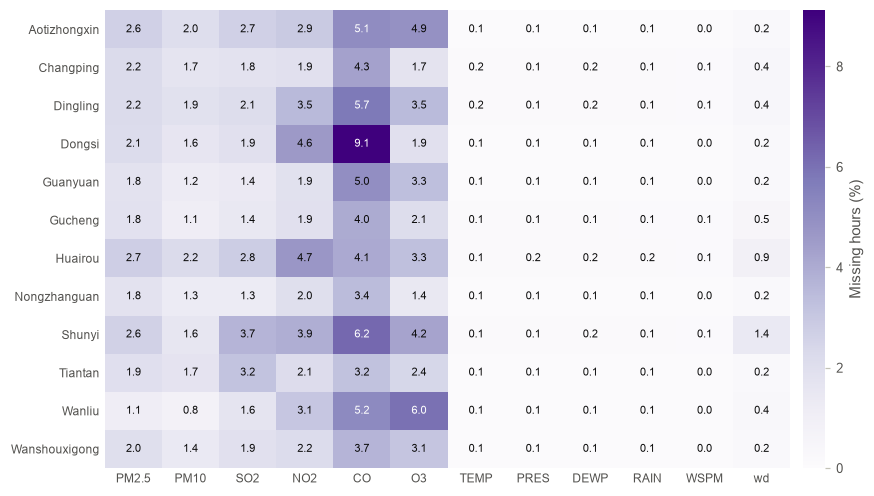

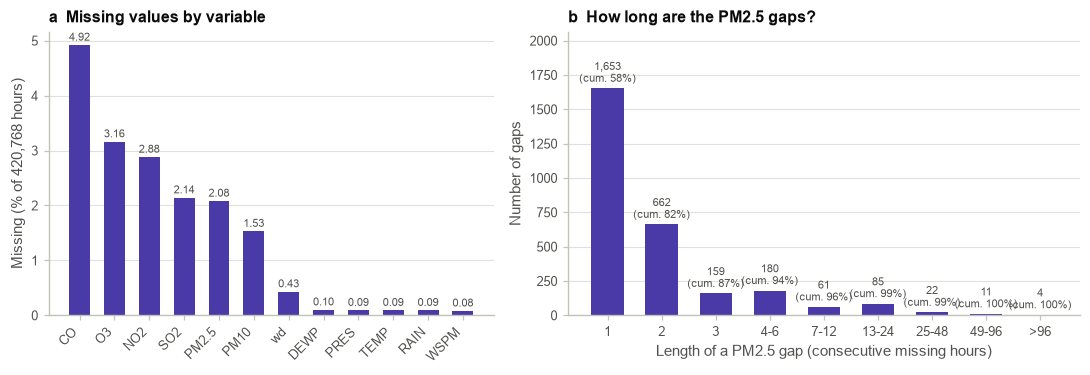

In [3]:
audit, gaps = D.audit(raw)
print(json.dumps(audit, indent=1))
RES["audit"] = audit
mm = D.missing_matrix(raw)
mm.round(2).to_csv(C.RES_DIR / "missing_by_station.csv")
V.missing_heatmap(mm)
V.missing_profile(audit["missing_pct"], gaps)
RES["missing_station_extremes"] = {"CO_max_station": mm["CO"].idxmax(), "CO_max_pct": jround(mm["CO"].max(), 2),
                                   "PM25_max_station": mm["PM2.5"].idxmax(), "PM25_max_pct": jround(mm["PM2.5"].max(), 2)}

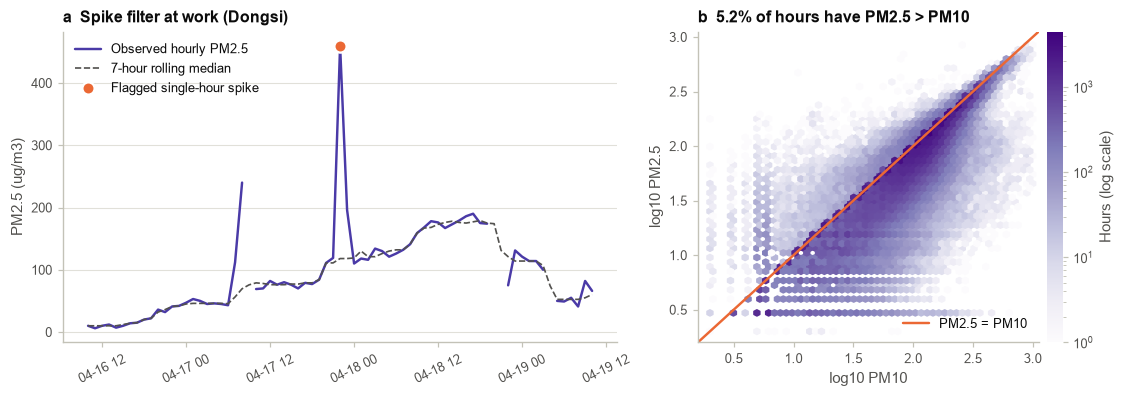

,Variable,IQR outliers (raw) %,IQR outliers (log scale) %
0,PM2.5,4.65,0.00
1,PM10,3.54,0.20
2,SO2,8.64,0.01
3,NO2,1.72,1.61
4,CO,7.01,0.31
5,O3,4.07,0.00
6,TEMP,0.00,0.00
7,PRES,0.00,0.00
8,DEWP,0.00,0.00
9,RAIN,3.93,3.93


In [4]:
# Outliers: instrument caps, the Hampel filter for isolated spikes, and the PM2.5 <= PM10 consistency rule
flags_all = pd.concat([D.hampel_flags(g.set_index("datetime")["PM2.5"]) for _, g in raw.groupby("station")])
RES["hampel_total_flags"] = int(flags_all.sum())
dong_raw = raw[raw.station == C.TARGET_STATION].set_index("datetime").sort_index()
dong_flags = D.hampel_flags(dong_raw["PM2.5"])
both = raw.dropna(subset=["PM2.5", "PM10"])
RES["spike_example"] = V.outlier_panels(dong_raw, dong_flags, both)

# IQR fences for comparison: on the raw scale they flag a large share of genuine haze hours
iqr_rows = []
for col in C.NUMERIC:
    s = raw[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    hi, lo = q3 + 1.5 * (q3 - q1), q1 - 1.5 * (q3 - q1)
    ls = np.log1p(s.clip(lower=0))
    l1, l3 = ls.quantile([0.25, 0.75])
    iqr_rows.append({"Variable": col, "IQR outliers (raw) %": jround(100 * ((s > hi) | (s < lo)).mean(), 2),
                     "IQR outliers (log scale) %": jround(100 * ((ls > l3 + 1.5 * (l3 - l1)) | (ls < l1 - 1.5 * (l3 - l1))).mean(), 2)})
iqr = pd.DataFrame(iqr_rows)
iqr.to_csv(C.RES_DIR / "iqr_outliers.csv", index=False)
RES["iqr_outliers"] = iqr.to_dict("records")
iqr

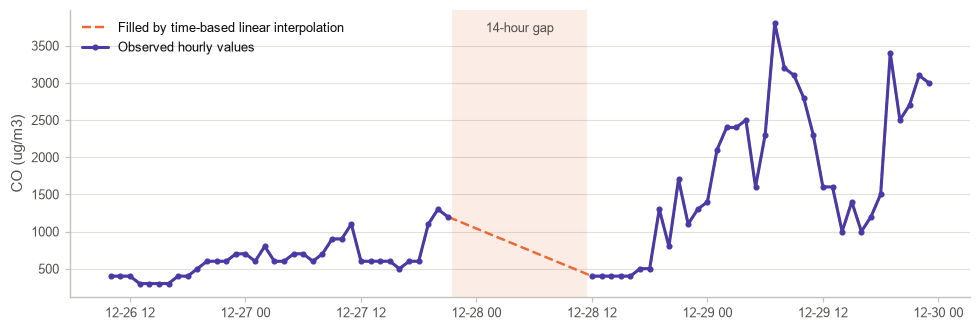

,cap_removed_PM2.5,cap_removed_PM10,cap_removed_CO,cap_removed_O3,hampel_spikes_PM2.5,interpolated_PM2.5,interpolated_PM10,interpolated_SO2,interpolated_NO2,interpolated_CO,interpolated_O3,interpolated_TEMP,interpolated_PRES,interpolated_DEWP,interpolated_RAIN,interpolated_WSPM,ffilled_wd,remaining_missing_any
Dongsi,0,0,10,16,15,502,359,467,390,633,484,20,20,20,20,14,78,3658


In [5]:
# Clean every station (caps -> NaN, Hampel spikes -> NaN, gaps <= 24 h interpolated in time)
cleaned, logs = {}, {}
for st, g in raw.groupby("station"):
    cleaned[st], logs[st] = D.clean_station(g)
clean_log = pd.DataFrame(logs).T
clean_log.to_csv(C.RES_DIR / "cleaning_log.csv")
RES["cleaning_totals"] = {k: int(v) for k, v in clean_log.sum().items()}
RES["cleaning_dongsi"] = {k: int(v) for k, v in clean_log.loc[C.TARGET_STATION].items()}
example = V.imputation_example(dong_raw, cleaned[C.TARGET_STATION], col="CO")
RES["imputation_example"] = example
clean_log.loc[[C.TARGET_STATION]]

In [6]:
# Screened data for exploration: caps and isolated spikes removed, but nothing interpolated
eda = []
for st, g in raw.groupby("station"):
    g = g.set_index("datetime").sort_index().copy()
    g.loc[g["PM2.5"] >= 999, "PM2.5"] = np.nan
    g.loc[g["PM10"] >= 999, "PM10"] = np.nan
    g.loc[g["CO"] >= 10000, "CO"] = np.nan
    g.loc[g["O3"] > 500, "O3"] = np.nan
    g.loc[D.hampel_flags(g["PM2.5"]), "PM2.5"] = np.nan
    eda.append(g.reset_index())
eda = pd.concat(eda, ignore_index=True)
eda["season"] = D.season_of(eda["month"].to_numpy())
eda["heating"] = D.heating_flag(eda["datetime"])
summary = eda[C.NUMERIC].describe(percentiles=[0.25, 0.5, 0.75]).T
summary["IQR"] = summary["75%"] - summary["25%"]
summary["CV"] = summary["std"] / summary["mean"]
summary["skewness"] = eda[C.NUMERIC].skew()
summary["kurtosis"] = eda[C.NUMERIC].kurt()
summary = summary[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "IQR", "CV", "skewness", "kurtosis"]].round(2)
summary.to_csv(C.RES_DIR / "summary_statistics.csv")
RES["summary"] = {k: {kk: jround(vv, 2) for kk, vv in v.items()} for k, v in summary.T.to_dict().items()}
summary

,count,mean,std,min,25%,50%,75%,max,IQR,CV,skewness,kurtosis
PM2.5,411738.0,79.79,80.78,2.00,20.0,55.0,111.0,957.0,91.0,1.01,2.01,5.91
PM10,414316.0,104.60,91.74,2.00,36.0,82.0,145.0,995.0,109.0,0.88,1.88,6.13
SO2,411747.0,15.83,21.65,0.29,3.0,7.0,20.0,500.0,17.0,1.37,3.01,14.19
NO2,408652.0,50.64,35.13,1.03,23.0,43.0,71.0,290.0,48.0,0.69,1.05,1.20
CO,400011.0,1229.54,1155.61,100.00,500.0,900.0,1500.0,9900.0,1000.0,0.94,2.54,9.06
O3,407473.0,57.33,56.29,0.21,11.0,45.0,82.0,500.0,71.0,0.98,1.46,2.38
TEMP,420370.0,13.54,11.44,-19.90,3.1,14.5,23.3,41.6,20.2,0.84,-0.10,-1.14
PRES,420375.0,1010.75,10.47,982.40,1002.3,1010.4,1019.0,1042.8,16.7,0.01,0.11,-0.83
DEWP,420365.0,2.49,13.79,-43.40,-8.9,3.1,15.1,29.1,24.0,5.54,-0.19,-1.13
RAIN,420378.0,0.06,0.82,0.00,0.0,0.0,0.0,72.5,0.0,12.73,30.04,1345.51


## 3. Mine: how PM2.5 moves in time (trend, seasonality, daily cycle, persistence)

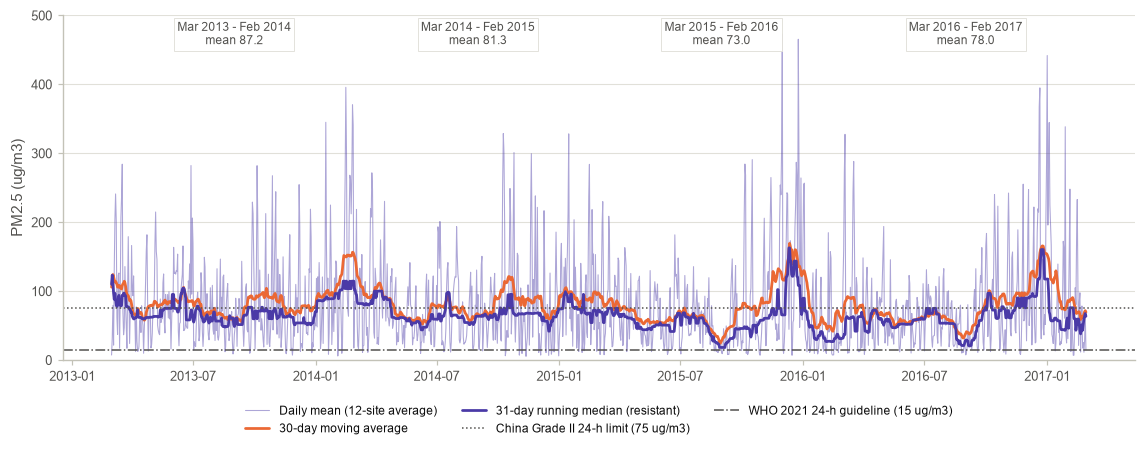

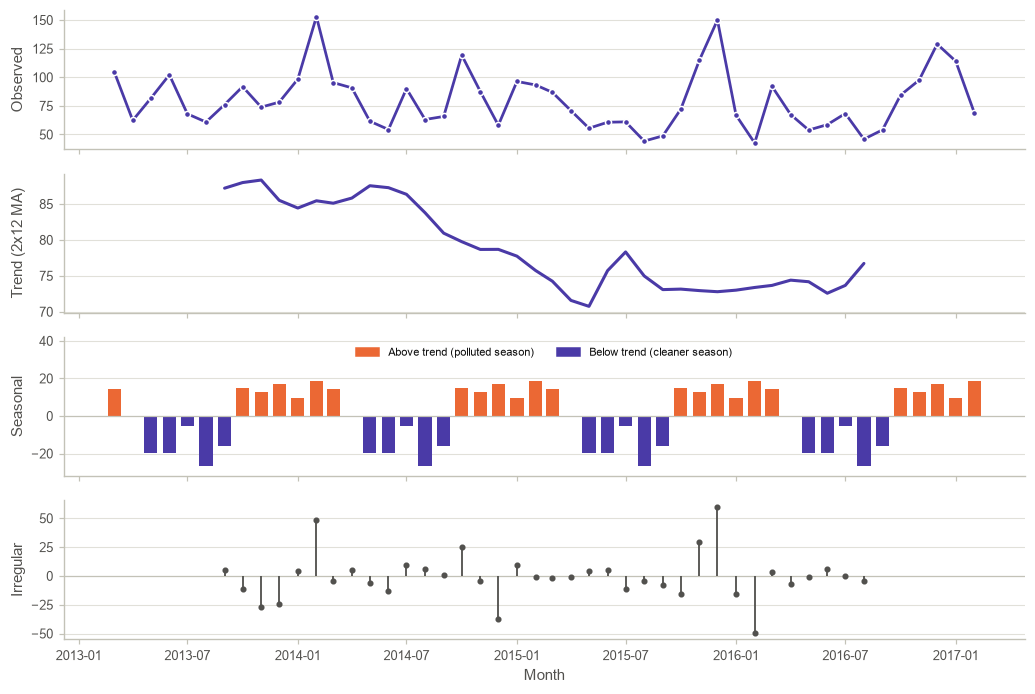

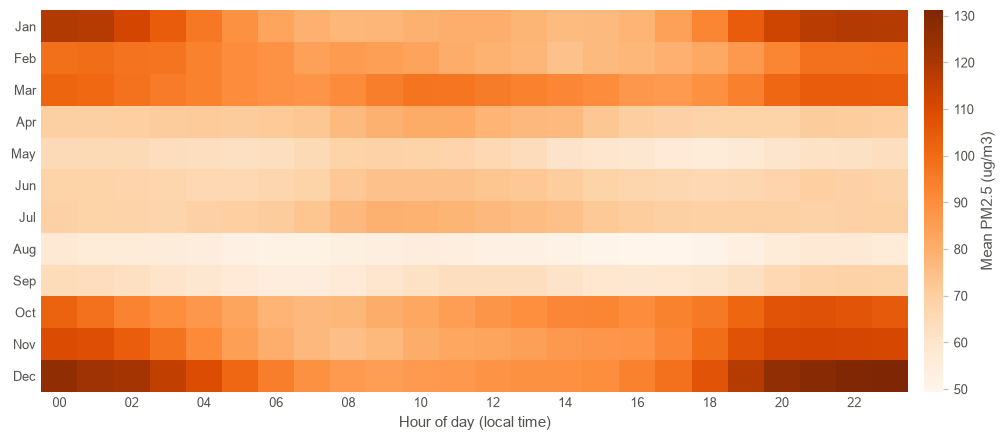

{'peak_cell': [12, 23, 131.2],
 'low_cell': [8, 17, 49.4],
 'winter_night_vs_afternoon': [123.5, 83.7],
 'summer_night_vs_afternoon': [69.0, 71.4]}

In [7]:
station_daily = eda.set_index("datetime").groupby("station")["PM2.5"].resample("D").mean().unstack(0)
daily = station_daily.mean(axis=1)
RES["seasonal_year_means"] = V.long_term(daily)
RES["days_city_mean_above_75_pct"] = jround(100 * (daily > C.LIMIT_PM25).mean(), 2)
RES["days_city_mean_above_15_pct"] = jround(100 * (daily > C.WHO_24H).mean(), 2)
RES["worst_day"] = {"date": str(daily.idxmax().date()), "value": jround(daily.max(), 1)}
RES["best_day"] = {"date": str(daily.idxmin().date()), "value": jround(daily.min(), 1)}
monthly = daily.resample("MS").mean()
trend, seasonal, resid, sidx = V.decomposition(monthly)
RES["seasonal_index"] = {int(k): jround(v, 1) for k, v in sidx.items()}
RES["trend_first_last"] = [jround(trend.dropna().iloc[0], 1), jround(trend.dropna().iloc[-1], 1),
                           str(trend.dropna().index[0].date()), str(trend.dropna().index[-1].date())]
RES["resid_sd"] = jround(resid.std(), 2)
RES["resid_max"] = {"month": str(resid.abs().idxmax().date()), "value": jround(resid.loc[resid.abs().idxmax()], 1)}
hm = V.hour_month_heatmap(eda)
RES["hour_month"] = {"peak_cell": [int(hm.stack().idxmax()[0]), int(hm.stack().idxmax()[1]), jround(hm.values.max(), 1)],
                     "low_cell": [int(hm.stack().idxmin()[0]), int(hm.stack().idxmin()[1]), jround(hm.values.min(), 1)],
                     "winter_night_vs_afternoon": [jround(hm.loc[[12, 1], [21, 22, 23, 0]].values.mean(), 1),
                                                   jround(hm.loc[[12, 1], [13, 14, 15, 16]].values.mean(), 1)],
                     "summer_night_vs_afternoon": [jround(hm.loc[[6, 7], [21, 22, 23, 0]].values.mean(), 1),
                                                   jround(hm.loc[[6, 7], [13, 14, 15, 16]].values.mean(), 1)]}
RES["hour_month"]

## 4. Mine: probability distributions (continuous and discrete)

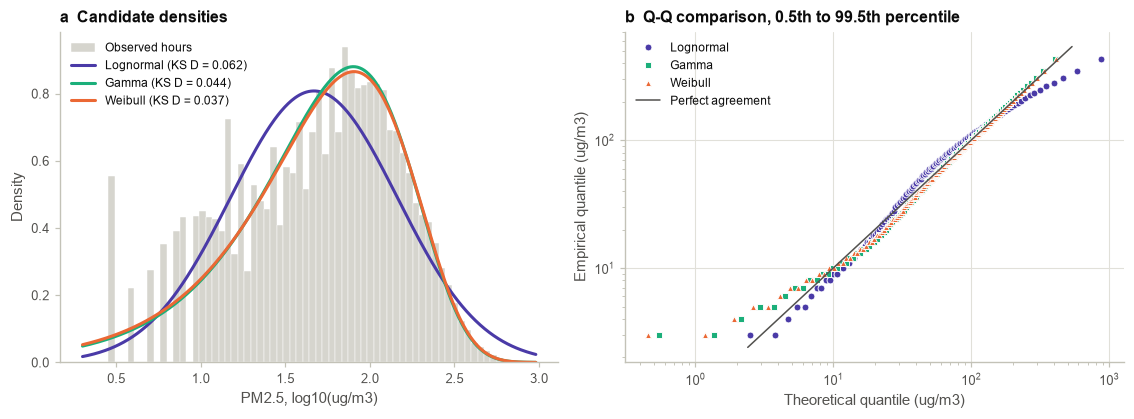

,AIC,BIC,KS_D
Lognormal,4439324.959118,4439346.815403,0.061705
Gamma,4428700.523434,4428722.379719,0.043842
Weibull,4429530.272263,4429552.128548,0.036964


In [8]:
x = eda["PM2.5"].dropna().to_numpy()
fits = S.fit_continuous(x)
V.continuous_fit(x, fits)
RES["continuous_fits"] = {k: {kk: (jround(vv, 4) if not isinstance(vv, list) else [jround(p, 4) for p in vv]) for kk, vv in v.items()}
                          for k, v in fits.items()}
RES["pm25_log_mean_sd"] = [jround(np.log(x).mean(), 3), jround(np.log(x).std(), 3)]
RES["pm25_n"] = int(len(x))
pd.DataFrame(fits).T[["AIC", "BIC", "KS_D"]]

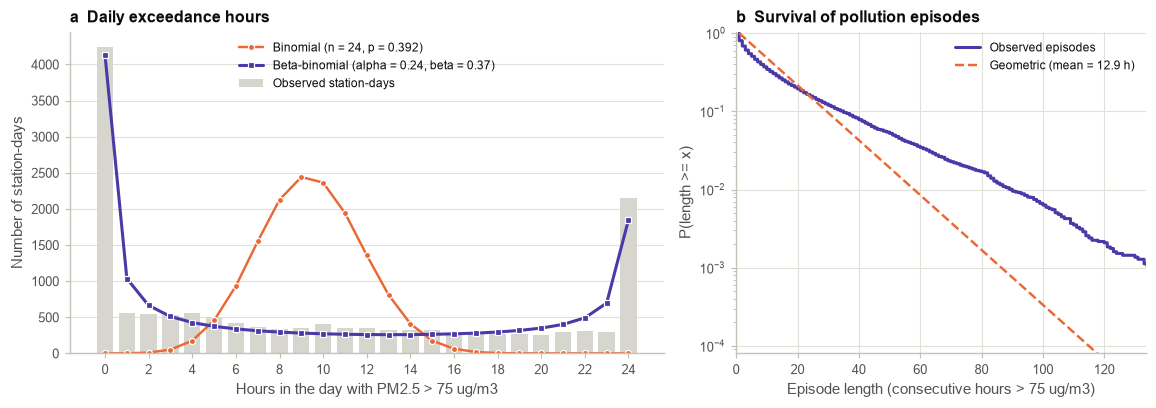

{'station_days': 14908,
 'mean_k': 9.417,
 'var_k': 82.35,
 'binom_var': 5.72,
 'p_hat': 0.3924,
 'alpha': 0.2445,
 'beta': 0.3652,
 'icc': 0.6213,
 'aic_binom': 299992.9,
 'aic_betabinom': 82425.5,
 'obs_0': 4244,
 'obs_24': 2148,
 'exp_bin_0': 0.1,
 'exp_bin_24': 3e-06,
 'exp_bb_0': 4129.6,
 'exp_bb_24': 1848.3,
 'episodes': 12492,
 'episode_mean': 12.88,
 'episode_median': 6.0,
 'episode_max': 167,
 'episode_ge24_obs_pct': 16.43,
 'episode_ge24_geom_pct': 15.59,
 'episode_ge72_obs_pct': 2.19,
 'episode_ge72_geom_pct': 0.322}

In [9]:
# Discrete: hours per day above 75 ug/m3 (complete station-days only) and the length of exceedance episodes
full = eda.dropna(subset=["PM2.5"]).assign(date=lambda d: d["datetime"].dt.floor("D")) \
          .groupby(["station", "date"])["PM2.5"].agg(n="size", k=lambda s: int((s > C.LIMIT_PM25).sum()))
full = full[full["n"] == 24]
k = full["k"].to_numpy()
a_bb, b_bb, ll_bb = S.fit_betabinom(k, 24)
p_hat = k.mean() / 24
ll_bin = stats.binom.logpmf(k, 24, p_hat).sum()
episodes = []
for st, g in eda.sort_values("datetime").groupby("station"):
    above = (g["PM2.5"] > C.LIMIT_PM25).to_numpy() & g["PM2.5"].notna().to_numpy()
    episodes.extend(D.run_lengths(above))
episodes = np.array(episodes)
obs, e_bin, e_bb = V.discrete_fit(k, 24, a_bb, b_bb, episodes)
rho_icc = 1 / (a_bb + b_bb + 1)        # intra-day correlation implied by the beta-binomial
RES["discrete"] = {"station_days": int(len(k)), "mean_k": jround(k.mean(), 3), "var_k": jround(k.var(), 2),
                   "binom_var": jround(24 * p_hat * (1 - p_hat), 2), "p_hat": jround(p_hat, 4),
                   "alpha": jround(a_bb, 4), "beta": jround(b_bb, 4), "icc": jround(rho_icc, 4),
                   "aic_binom": jround(2 - 2 * ll_bin, 1), "aic_betabinom": jround(4 - 2 * ll_bb, 1),
                   "obs_0": int(obs[0]), "obs_24": int(obs[24]), "exp_bin_0": jround(e_bin[0], 2), "exp_bin_24": jround(e_bin[24], 6),
                   "exp_bb_0": jround(e_bb[0], 1), "exp_bb_24": jround(e_bb[24], 1),
                   "episodes": int(len(episodes)), "episode_mean": jround(episodes.mean(), 2),
                   "episode_median": jround(np.median(episodes), 1), "episode_max": int(episodes.max()),
                   "episode_ge24_obs_pct": jround(100 * (episodes >= 24).mean(), 2),
                   "episode_ge24_geom_pct": jround(100 * (1 - 1 / episodes.mean()) ** 23, 2),
                   "episode_ge72_obs_pct": jround(100 * (episodes >= 72).mean(), 2),
                   "episode_ge72_geom_pct": jround(100 * (1 - 1 / episodes.mean()) ** 71, 3)}
RES["discrete"]

## 5. Mine: space and weather (several batches, a third variable, correlation)

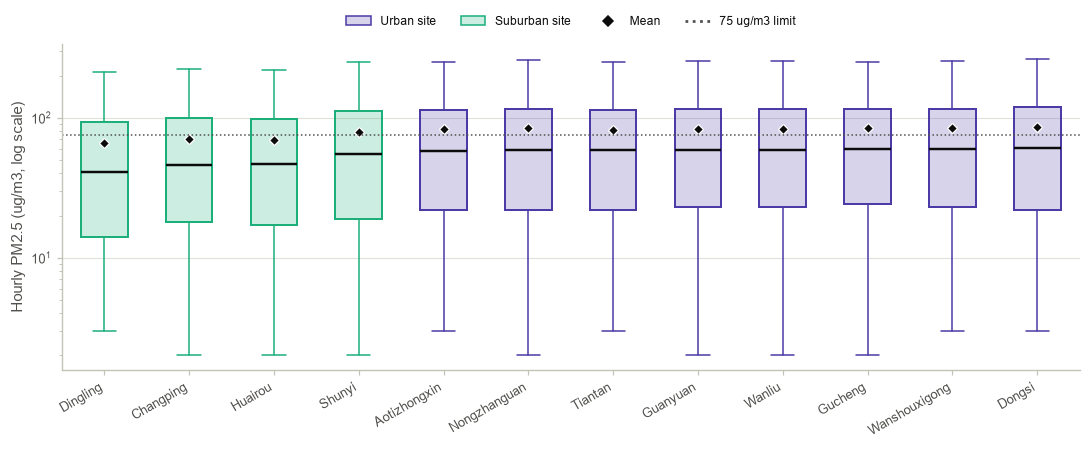

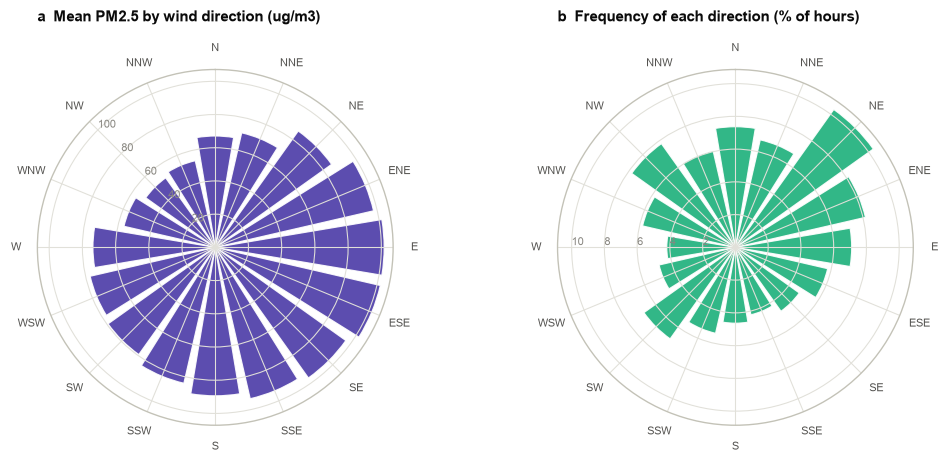

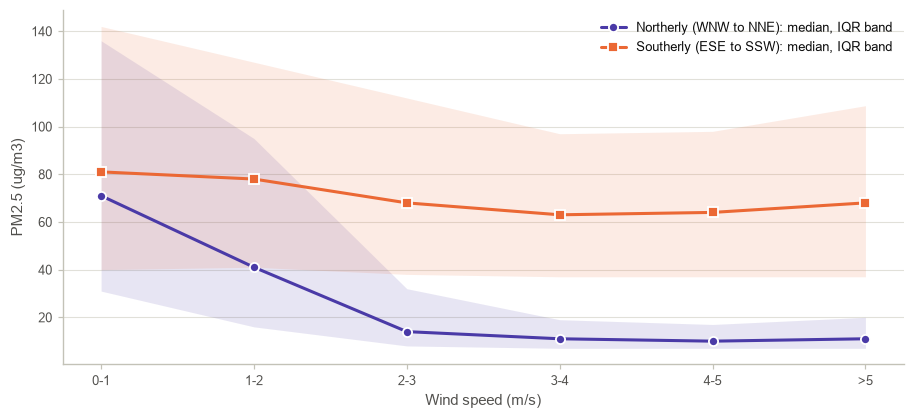

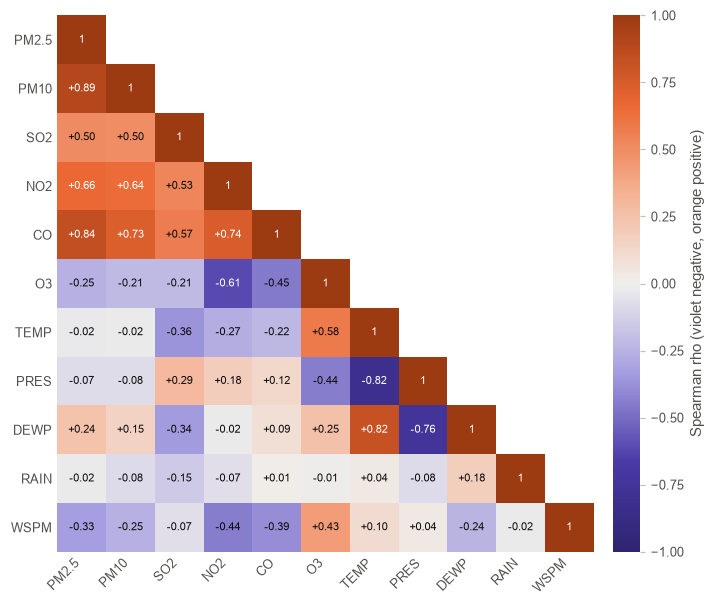

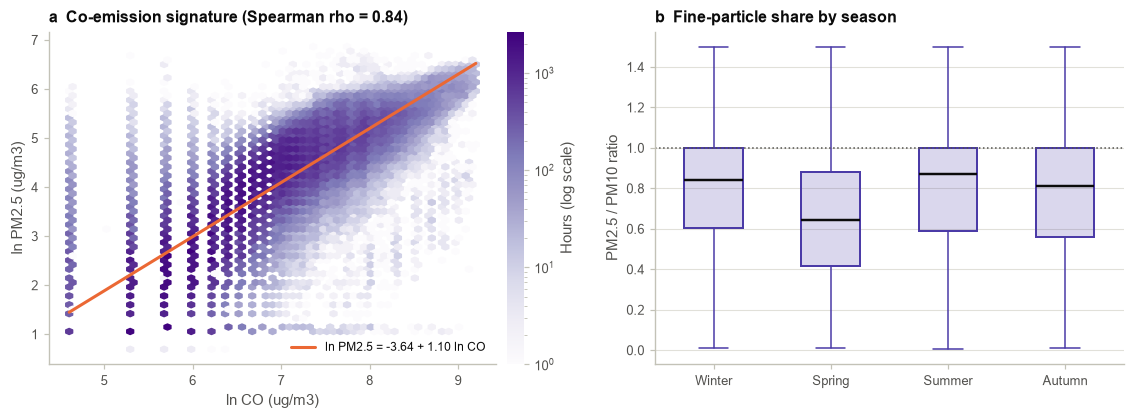

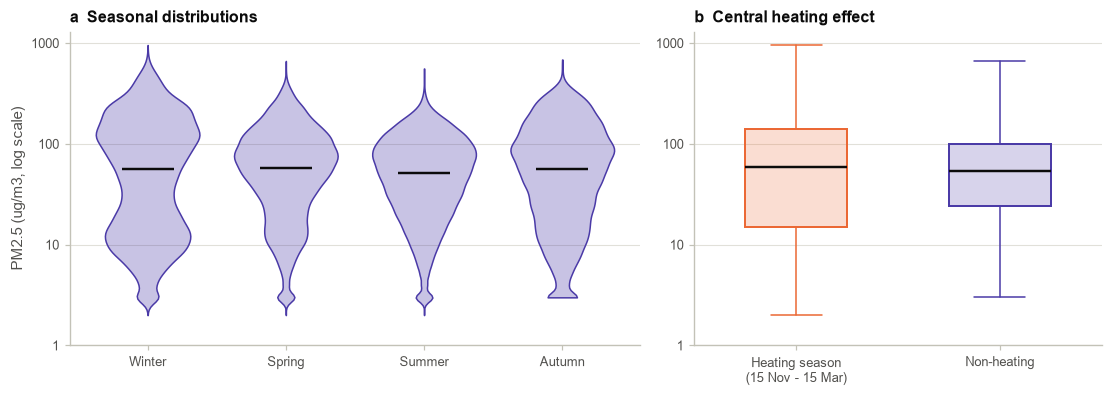

{'kruskal_H': 745.5,
 'kruskal_p': 2.8269747983308382e-161,
 'epsilon2': 0.0018,
 'season_median': {'Winter': 56.0,
  'Spring': 58.0,
  'Summer': 51.0,
  'Autumn': 56.0},
 'season_mean': {'Winter': 95.5,
  'Spring': 76.9,
  'Summer': 64.7,
  'Autumn': 82.3},
 'season_p90': {'Winter': 241.0,
  'Spring': 169.0,
  'Summer': 137.0,
  'Autumn': 201.0},
 'heating_median': 59.0,
 'nonheating_median': 54.0,
 'heating_mean': 94.8,
 'nonheating_mean': 72.3,
 'heating_p90': 238.0,
 'nonheating_p90': 159.0,
 'mw_p': 4.3352452480628e-53,
 'mw_auc': 0.515}

In [10]:
order = V.station_boxplots(eda)
groups = [eda.loc[eda.station == s, "PM2.5"].dropna() for s in order]
H, pH = stats.kruskal(*groups)
urb = eda.loc[eda.station.isin(C.URBAN), "PM2.5"].dropna()
sub = eda.loc[eda.station.isin(C.SUBURBAN), "PM2.5"].dropna()
U, pU = stats.mannwhitneyu(urb, sub)
RES["stations"] = {"order_by_median": order,
                   "medians": {s: jround(g.median(), 1) for s, g in zip(order, groups)},
                   "means": {s: jround(g.mean(), 1) for s, g in zip(order, groups)},
                   "kruskal_H": jround(H, 1), "kruskal_p": float(pH), "epsilon2": jround(S.epsilon_squared(H, sum(map(len, groups))), 4),
                   "urban_median": jround(urb.median(), 1), "suburban_median": jround(sub.median(), 1),
                   "urban_mean": jround(urb.mean(), 1), "suburban_mean": jround(sub.mean(), 1),
                   "mw_auc": jround(U / (len(urb) * len(sub)), 4), "mw_p": float(pU)}
wind = V.wind_polar(eda)
RES["wind"] = {"mean": {d: jround(v, 1) for d, v in wind["mean"].items()},
               "freq_pct": {d: jround(100 * v / wind["size"].sum(), 2) for d, v in wind["size"].items()}}
RES["wind_speed_sector"] = V.wind_speed_conditional(eda)
corr = V.spearman_triangle(eda)
RES["spearman_pm25"] = {k: jround(v, 3) for k, v in corr["PM2.5"].items()}
RES["spearman_pairs"] = {"PM10~CO": jround(corr.loc["PM10", "CO"], 3), "NO2~CO": jround(corr.loc["NO2", "CO"], 3),
                         "TEMP~DEWP": jround(corr.loc["TEMP", "DEWP"], 3), "TEMP~PRES": jround(corr.loc["TEMP", "PRES"], 3),
                         "O3~TEMP": jround(corr.loc["O3", "TEMP"], 3), "O3~NO2": jround(corr.loc["O3", "NO2"], 3)}
RES["co_ratio"] = V.co_and_ratio(eda)
RES["season"] = V.season_heating(eda)
RES["season"]

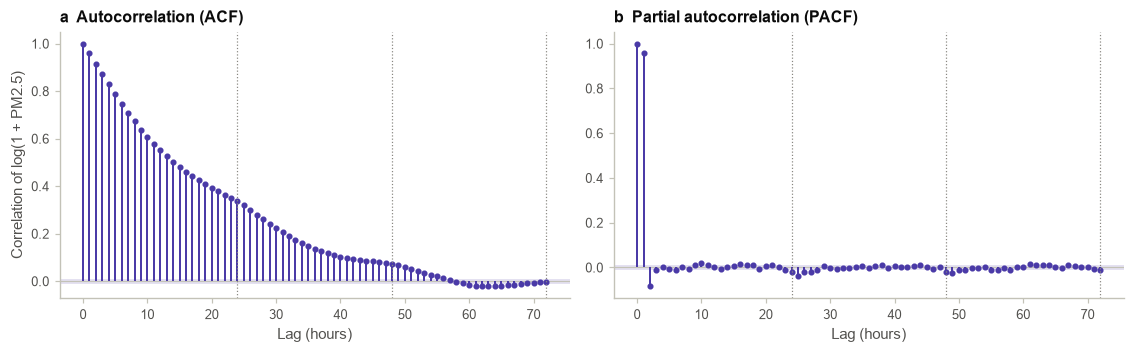

{'lag1': 0.96,
 'lag6': 0.747,
 'lag12': 0.552,
 'lag24': 0.336,
 'lag48': 0.074,
 'lag72': -0.004,
 'pacf1': 0.96,
 'pacf2': -0.084,
 'pacf24': -0.02,
 'band': 0.0105}

In [11]:
# Autocorrelation of the target station's (cleaned) hourly series justifies the LSTM look-back window
dong = D.add_features(cleaned[C.TARGET_STATION])
series = dong["log_PM2.5"].interpolate(limit_direction="both").to_numpy()
r_acf, r_pacf, band = V.acf_pacf(series, 72)
RES["acf"] = {"lag1": jround(r_acf[1], 3), "lag6": jround(r_acf[6], 3), "lag12": jround(r_acf[12], 3),
              "lag24": jround(r_acf[24], 3), "lag48": jround(r_acf[48], 3), "lag72": jround(r_acf[72], 3),
              "pacf1": jround(r_pacf[1], 3), "pacf2": jround(r_pacf[2], 3), "pacf24": jround(r_pacf[24], 3), "band": jround(band, 4)}
RES["acf"]

## 6. Interact: exploratory dashboard
`dashboard/index.html` is a single self-contained page (no internet needed). It lets the reader pick a
station, a pollutant and a date range, and redraws a daily time series, an hour-by-month heat map and a
wind-direction profile on the fly.

In [12]:
dsub = eda.assign(date=eda["datetime"].dt.strftime("%Y-%m-%d"))
dash = {"stations": sorted(eda["station"].unique().tolist()), "vars": C.POLLUTANTS, "dirs": C.WIND_DIRS}
daily_tab = dsub.groupby(["station", "date"])[C.POLLUTANTS].mean().round(1)
dash["dates"] = sorted(dsub["date"].unique().tolist())
dash["daily"] = {st: {v: [None if pd.isna(x_) else float(x_) for x_ in daily_tab.loc[st, v].reindex(dash["dates"])]
                      for v in C.POLLUTANTS} for st in dash["stations"]}
hm_tab = eda.groupby(["station", "month", "hour"])[C.POLLUTANTS].mean().round(1)
dash["hm"] = {st: {v: hm_tab.loc[st, v].unstack().reindex(index=range(1, 13), columns=range(24)).values.tolist()
                   for v in C.POLLUTANTS} for st in dash["stations"]}
wd_tab = eda.groupby(["station", "wd"])[C.POLLUTANTS].mean().round(1)
dash["wd"] = {st: {v: [float(wd_tab.loc[(st, d), v]) for d in C.WIND_DIRS] for v in C.POLLUTANTS} for st in dash["stations"]}
tpl = (ROOT / "src" / "dashboard_template.html").read_text(encoding="utf-8")
(C.DASH_DIR / "index.html").write_text(tpl.replace("/*__DATA__*/null", json.dumps(dash, separators=(",", ":"))), encoding="utf-8")
print("dashboard written:", C.DASH_DIR / "index.html")

dashboard written: C:\Users\nakul\AppData\Roaming\Claude\scratch-workspaces\635db47b-82a4-4829-a53f-a8bb9dba6efa\bf12d992-1e38-4815-99e9-735d88a9c900\scratch-2026-10-12-3f46f7\Naveena_24AD070\dashboard\index.html


## 7. Transform: features, chronological split and windows for the LSTM

In [13]:
FEATS = D.MODEL_FEATURES
dong = dong.copy()
train_mask = dong.index <= pd.Timestamp(C.TRAIN_END)
val_mask = (dong.index > pd.Timestamp(C.TRAIN_END)) & (dong.index <= pd.Timestamp(C.VAL_END))
test_mask = dong.index > pd.Timestamp(C.VAL_END)
mu = dong.loc[train_mask, FEATS].mean()
sd = dong.loc[train_mask, FEATS].std()
F = ((dong[FEATS] - mu) / sd).to_numpy(np.float32)          # scaling learned on training hours only
t_mu, t_sd = mu["log_PM2.5"], sd["log_PM2.5"]
target = F[:, FEATS.index("log_PM2.5")]
feat_ok = ~np.isnan(F).any(axis=1)
target_ok = ~np.isnan(target)
b1, b2 = int(train_mask.sum()), int(train_mask.sum() + val_mask.sum())
inv = lambda z: np.expm1(z * t_sd + t_mu)                  # standardised log -> ug/m3
RES["split"] = {"train": [str(dong.index[0]), str(dong.index[b1 - 1]), b1],
                "val": [str(dong.index[b1]), str(dong.index[b2 - 1]), b2 - b1],
                "test": [str(dong.index[b2]), str(dong.index[-1]), len(dong) - b2],
                "hours_with_complete_features_pct": jround(100 * feat_ok.mean(), 2)}
RES["features"] = FEATS
RES["split"]

{'train': ['2013-03-01 00:00:00', '2015-02-28 23:00:00', 17520],
 'val': ['2015-03-01 00:00:00', '2016-02-29 23:00:00', 8784],
 'test': ['2016-03-01 00:00:00', '2017-02-28 23:00:00', 8760],
 'hours_with_complete_features_pct': 89.57}

## 8. Mine: LSTM model, basic hyper-parameter tuning and feature analysis

{'config': 1, 'lookback': 12, 'hidden': 32, 'train_windows': 13910, 'val_windows': 8778, 'epochs_run': 13, 'best_epoch': 7, 'val_rmse': 41.127, 'val_mae': 21.07, 'params': 15862, 'seconds': 37.1}


{'config': 2, 'lookback': 12, 'hidden': 64, 'train_windows': 13910, 'val_windows': 8778, 'epochs_run': 12, 'best_epoch': 6, 'val_rmse': 41.701, 'val_mae': 20.98, 'params': 57318, 'seconds': 31.5}


{'config': 3, 'lookback': 24, 'hidden': 32, 'train_windows': 13814, 'val_windows': 8778, 'epochs_run': 13, 'best_epoch': 7, 'val_rmse': 40.995, 'val_mae': 21.118, 'params': 15862, 'seconds': 53.6}


{'config': 4, 'lookback': 24, 'hidden': 64, 'train_windows': 13814, 'val_windows': 8778, 'epochs_run': 10, 'best_epoch': 4, 'val_rmse': 40.865, 'val_mae': 20.763, 'params': 57318, 'seconds': 50.1}


{'config': 5, 'lookback': 48, 'hidden': 32, 'train_windows': 13622, 'val_windows': 8778, 'epochs_run': 12, 'best_epoch': 6, 'val_rmse': 41.23, 'val_mae': 21.144, 'params': 15862, 'seconds': 79.2}


{'config': 6, 'lookback': 48, 'hidden': 64, 'train_windows': 13622, 'val_windows': 8778, 'epochs_run': 12, 'best_epoch': 6, 'val_rmse': 40.737, 'val_mae': 20.733, 'params': 57318, 'seconds': 112.3}


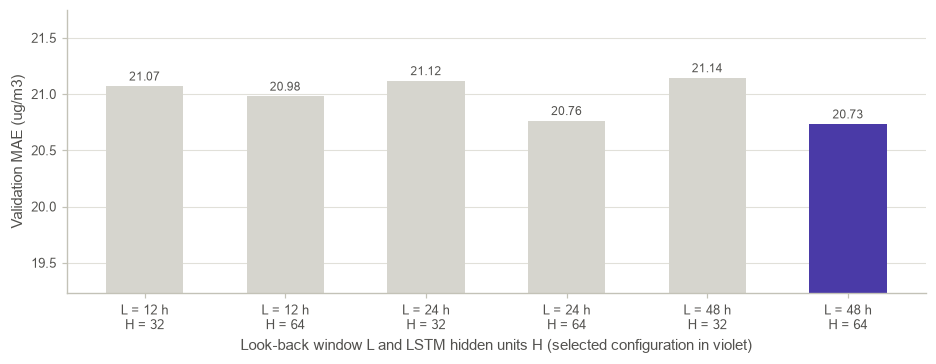

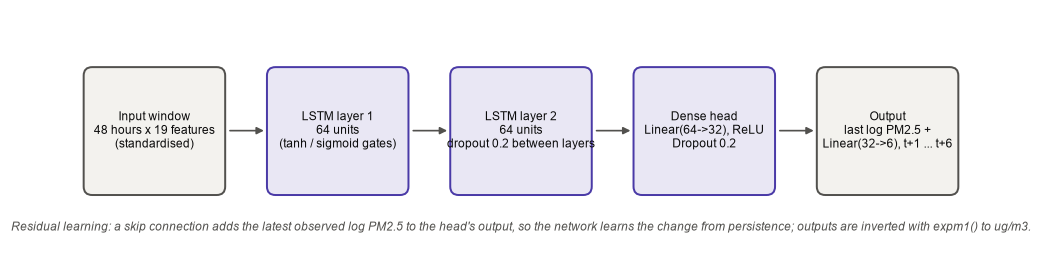

,config,lookback,hidden,train_windows,val_windows,epochs_run,best_epoch,val_rmse,val_mae,params,seconds
0,1,12,32,13910,8778,13,7,41.127,21.070,15862,37.1
1,2,12,64,13910,8778,12,6,41.701,20.980,57318,31.5
2,3,24,32,13814,8778,13,7,40.995,21.118,15862,53.6
3,4,24,64,13814,8778,10,4,40.865,20.763,57318,50.1
4,5,48,32,13622,8778,12,6,41.230,21.144,15862,79.2
5,6,48,64,13622,8778,12,6,40.737,20.733,57318,112.3


In [14]:
import torch
torch.set_num_threads(max(1, torch.get_num_threads()))
GRID = [(L, Hh) for L in (12, 24, 48) for Hh in (32, 64)]
FAST = __import__("os").environ.get("FAST_RUN") == "1"   # smoke-test switch
EPOCHS = 3 if FAST else 40
if FAST:
    GRID = GRID[2:3]
tuning, models = [], {}
t_start = time.time()
for cfg_id, (L, Hh) in enumerate(GRID, start=1):
    o_tr = M.valid_origins(feat_ok, target_ok, L, C.HORIZON, 0, b1)
    o_va = M.valid_origins(feat_ok, target_ok, L, C.HORIZON, b1, b2)
    Xtr, Ytr = M.make_windows(F, target, o_tr, L)
    Xva, Yva = M.make_windows(F, target, o_va, L)
    t0 = time.time()
    net, hist = M.train(Xtr, Ytr, Xva, Yva, inv, hidden=Hh, epochs=EPOCHS, patience=6, verbose=False,
                        anchor_idx=FEATS.index("log_PM2.5"))
    pv = inv(M.predict(net, Xva))
    row = {"config": cfg_id, "lookback": L, "hidden": Hh, "train_windows": int(len(Xtr)), "val_windows": int(len(Xva)),
           "epochs_run": len(hist["train_loss"]), "best_epoch": hist["best_epoch"],
           "val_rmse": jround(M.rmse(pv, inv(Yva)), 3), "val_mae": jround(M.mae(pv, inv(Yva)), 3),
           "params": int(sum(p.numel() for p in net.parameters())), "seconds": jround(time.time() - t0, 1)}
    print(row)
    tuning.append(row)
    models[cfg_id] = (net, hist, L)
best = min(tuning, key=lambda r: r["val_mae"])     # MAE is the headline metric
RES["tuning"] = tuning
RES["tuning_seconds"] = jround(time.time() - t_start, 1)
RES["best"] = best
net, hist, L = models[best["config"]]
torch.save(net.state_dict(), C.RES_DIR / "lstm_best.pt")
VR.tuning_chart(tuning, best["config"])
V.lstm_diagram(len(FEATS), L, best["hidden"], 2, C.HORIZON)
pd.DataFrame(tuning)

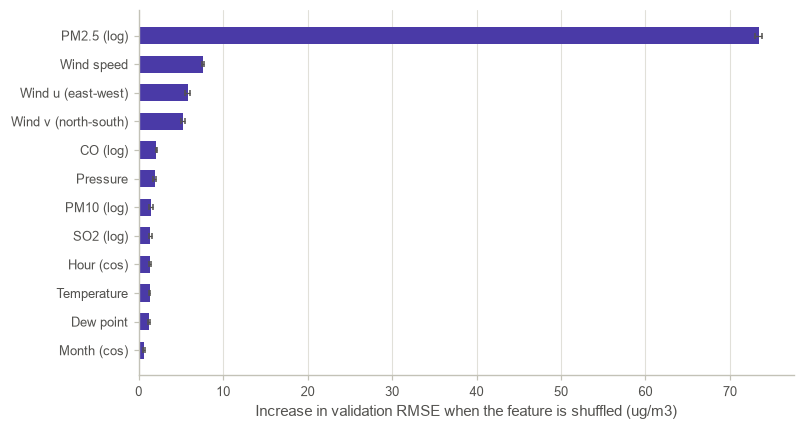

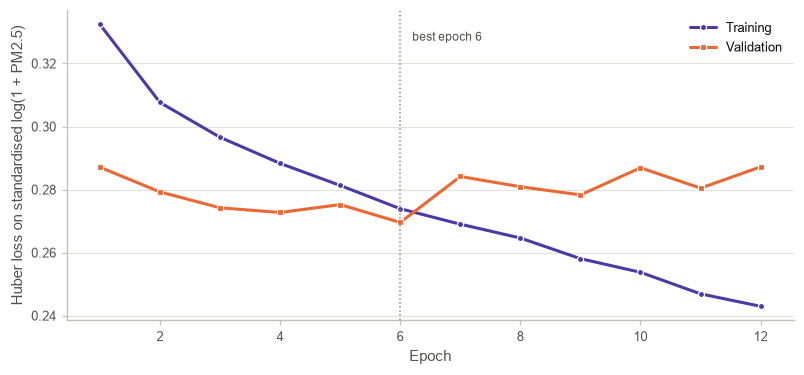

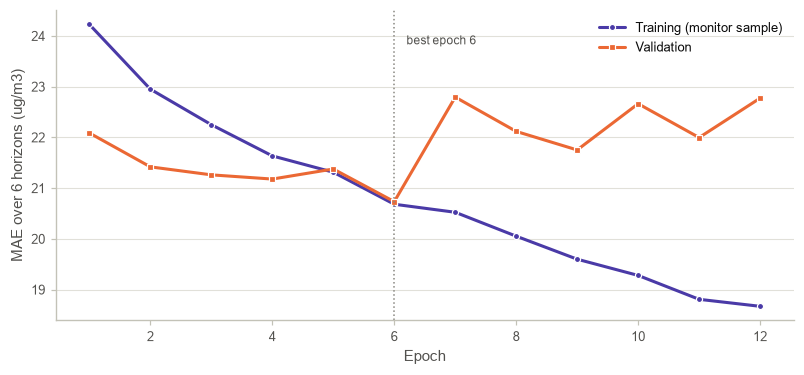

,feature,rmse_increase,sd
0,log_PM2.5,73.396618,0.456445
1,WSPM,7.613807,0.084686
2,wind_u,5.786170,0.323510
3,wind_v,5.245682,0.198394
4,log_CO,2.095775,0.022176
5,PRES,1.899386,0.166037
6,log_PM10,1.471802,0.200995
7,log_SO2,1.346983,0.182022


In [15]:
o_va = M.valid_origins(feat_ok, target_ok, L, C.HORIZON, b1, b2)
Xva, Yva = M.make_windows(F, target, o_va, L)
labels = {"log_PM2.5": "PM2.5 (log)", "log_PM10": "PM10 (log)", "log_SO2": "SO2 (log)", "log_NO2": "NO2 (log)",
          "log_CO": "CO (log)", "log_O3": "O3 (log)", "log_RAIN": "Rain (log)", "wind_u": "Wind u (east-west)",
          "wind_v": "Wind v (north-south)", "WSPM": "Wind speed", "TEMP": "Temperature", "PRES": "Pressure",
          "DEWP": "Dew point", "hour_sin": "Hour (sin)", "hour_cos": "Hour (cos)", "month_sin": "Month (sin)",
          "month_cos": "Month (cos)", "dow_sin": "Weekday (sin)", "dow_cos": "Weekday (cos)"}
base_rmse, imp = M.permutation_importance(net, Xva, Yva, inv, FEATS, repeats=5)
VR.importance_chart(imp, labels)
RES["perm_importance"] = {"base_val_rmse": jround(base_rmse, 3), "ranking": [{**d, "rmse_increase": jround(d["rmse_increase"], 3), "sd": jround(d["sd"], 3)} for d in imp]}
VR.learning_curves(hist)
RES["history"] = {k: ([jround(v, 4) for v in vals] if isinstance(vals, list) else vals) for k, vals in hist.items()}
pd.DataFrame(imp).head(8)

## 9. Represent and refine: evaluation on the untouched test year (March 2016 to February 2017)

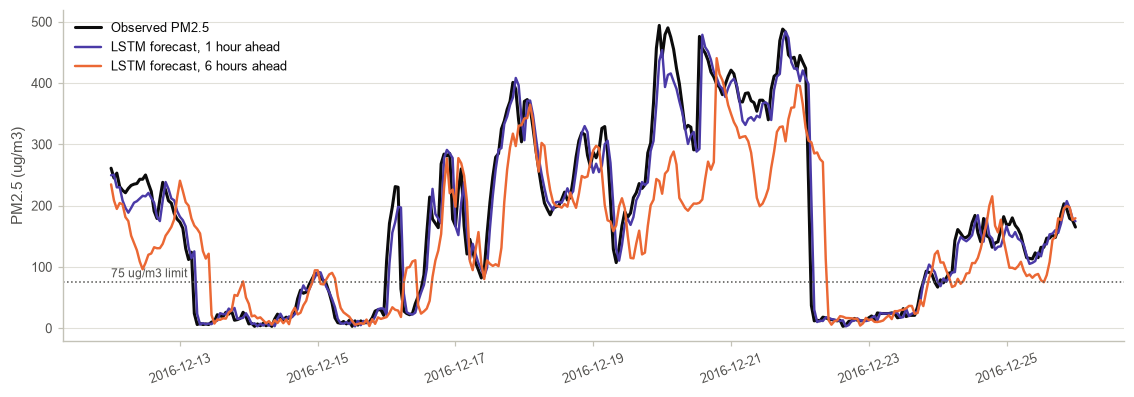

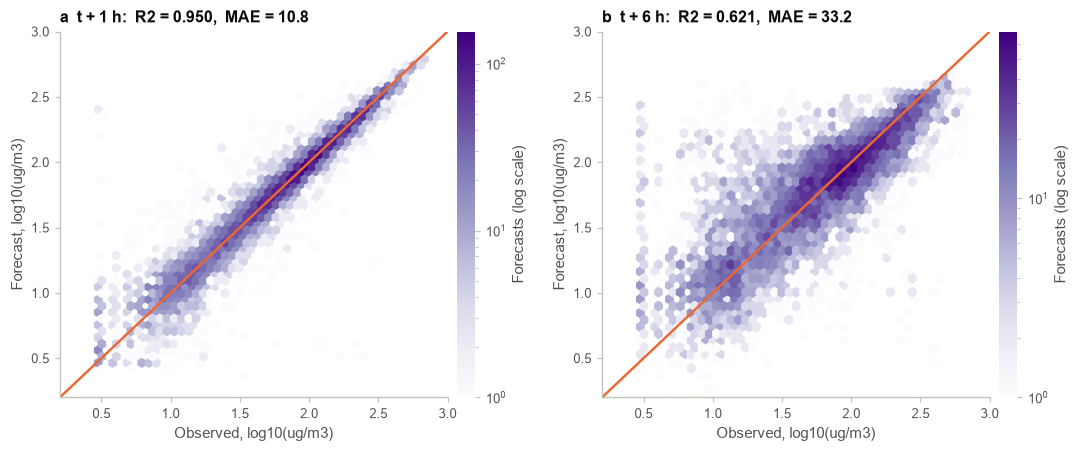

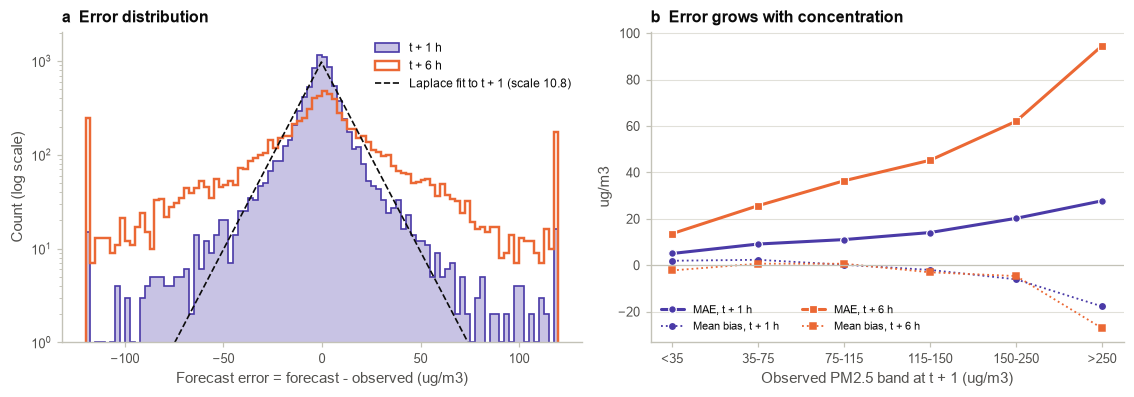

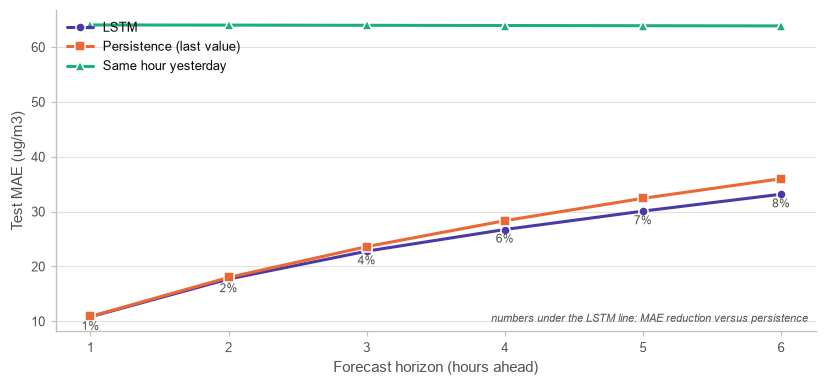

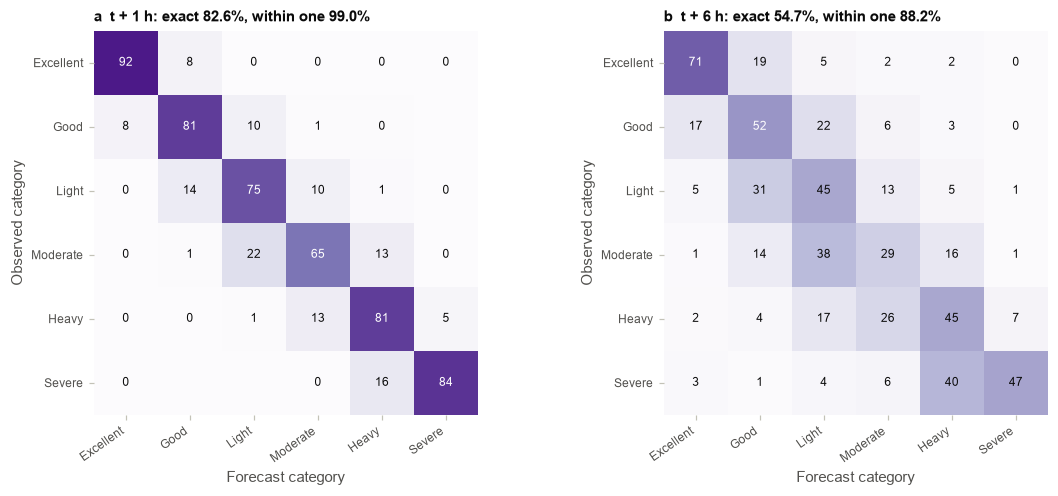

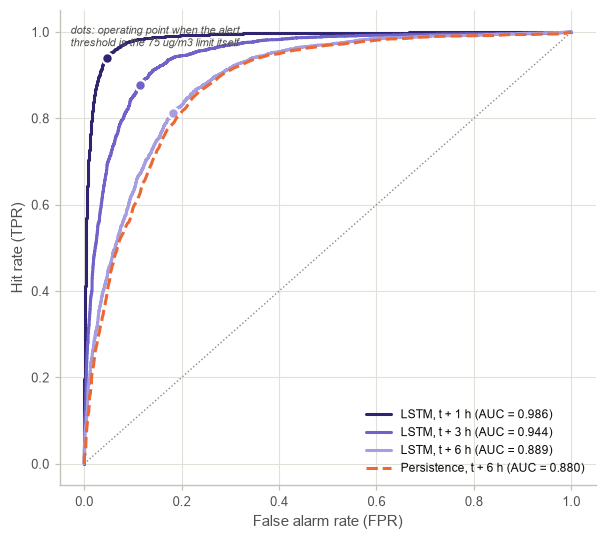

,LSTM MAE,Persistence MAE,Same-hour-yesterday MAE,LSTM R2
t+1,10.811,10.878,64.034,0.950
t+2,17.701,17.988,64.003,0.873
t+3,22.778,23.612,63.967,0.802
t+4,26.731,28.342,63.931,0.738
t+5,30.086,32.416,63.895,0.679
t+6,33.167,35.999,63.858,0.621


In [16]:
o_te = M.valid_origins(feat_ok, target_ok, L, C.HORIZON, b2, len(F))
Xte, Yte = M.make_windows(F, target, o_te, L)
P = inv(M.predict(net, Xte))
Y = inv(Yte)
pm = dong["PM2.5"].to_numpy()
persist = np.repeat(pm[o_te][:, None], C.HORIZON, axis=1)
snaive = np.stack([pm[o_te + h - 24] for h in range(1, C.HORIZON + 1)], axis=1)
tab_lstm, tab_p, tab_s = M.horizon_table(Y, P), M.horizon_table(Y, persist), M.horizon_table(Y, snaive)
RES["test"] = {"windows": int(len(Xte)), "lstm": tab_lstm, "persistence": tab_p, "seasonal_naive": tab_s,
               "lstm_mean_mae": jround(np.mean([r["MAE"] for r in tab_lstm]), 3),
               "persistence_mean_mae": jround(np.mean([r["MAE"] for r in tab_p]), 3),
               "lstm_mean_rmse": jround(np.mean([r["RMSE"] for r in tab_lstm]), 3),
               "persistence_mean_rmse": jround(np.mean([r["RMSE"] for r in tab_p]), 3)}
times = dong.index[o_te + 1]
# align the 6-hour-ahead forecast with the hour it refers to
p6_aligned = pd.Series(P[:, 5], index=dong.index[o_te + 6]).reindex(times)
VR.forecast_window(times, Y[:, 0], P[:, 0], p6_aligned.to_numpy(), "2016-12-12", "2016-12-26")
VR.scatter_pred_obs(Y, P, tab_lstm)
RES["residuals"] = VR.residuals(Y, P)
VR.horizon_skill(tab_lstm, tab_p, tab_s)
RES["aqi"] = VR.aqi_confusion(Y, P)
RES["roc"] = VR.exceedance_roc(Y, P, persist[:, 5])
pd.DataFrame({"LSTM MAE": [r["MAE"] for r in tab_lstm], "Persistence MAE": [r["MAE"] for r in tab_p],
              "Same-hour-yesterday MAE": [r["MAE"] for r in tab_s], "LSTM R2": [r["R2"] for r in tab_lstm]},
             index=[f"t+{h}" for h in range(1, 7)]).round(3)

In [17]:
RES["versions"] = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "torch": torch.__version__}
(C.RES_DIR / "results.json").write_text(json.dumps(RES, indent=1, default=str), encoding="utf-8")
print("saved", C.RES_DIR / "results.json")

saved C:\Users\nakul\AppData\Roaming\Claude\scratch-workspaces\635db47b-82a4-4829-a53f-a8bb9dba6efa\bf12d992-1e38-4815-99e9-735d88a9c900\scratch-2026-10-12-3f46f7\Naveena_24AD070\results\results.json
